# Практика: DBSCAN — плотностная кластеризация

## Что вы сделаете
В этом ноутбуке вы:

1. исследуете нелинейные 2D-датасеты и убедитесь в ограничениях K-Means;
2. построите **k-distance plot** и выберете оптимальный параметр `eps`;
3. применените **DBSCAN** и проанализируете результаты;
4. сравните DBSCAN с K-Means на нелинейных данных;
5. исследуете влияние гиперпараметров `eps` и `min_samples`;
6. применените DBSCAN к реальному датасету **Wine** и проанализируете шумовые точки;
7. сравните силуэт DBSCAN и K-Means, сделаете выводы.

## Важно
- Заполняйте все ячейки с пометкой `# YOUR CODE HERE`.
- Не удаляйте проверки: они подскажут, правильно ли вы идёте.
- Вопросы для размышления помогут вам глубже понять алгоритм.

## Датасеты
- **`make_moons`** и **`make_circles`** из `sklearn.datasets`: 2D-данные с нелинейными кластерами.
- **Wine** (`load_wine`): реальный многомерный датасет (13 признаков, 3 класса).

## Что сдавать
1. Заполненный ноутбук со всеми графиками.
2. Краткие выводы в конце каждого раздела.
3. Итоговый вывод: когда DBSCAN лучше K-Means и когда нет.

## Краткая теория

### Типы точек в DBSCAN

DBSCAN задаётся двумя параметрами: радиусом окрестности `eps` (ε) и минимальным числом точек `min_samples`.

- **Корневая точка** (core): в её ε-окрестности ≥ `min_samples` точек.
- **Граничная точка** (border): в её ε-окрестности < `min_samples`, но она достижима из корневой.
- **Шумовая точка** (noise): не является ни корневой, ни граничной → метка **-1**.

### Как работает алгоритм

1. Для каждой непосещённой точки найти её ε-окрестность.
2. Если точек ≥ `min_samples` — начать новый кластер.
3. Рекурсивно расширить кластер через цепочки плотно достижимых точек.
4. Оставшиеся точки → шум (метка -1).

### Как выбрать eps: k-distance plot

Для каждой точки вычисляют расстояние до её k-го ближайшего соседа (k = `min_samples`). Отсортированный по убыванию график этих расстояний называется **k-distance plot**. Резкий перегиб («локоть») указывает на оптимальное значение `eps`.

---
## Шаг 1. Импорты и настройки

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.datasets import make_moons, make_circles, load_wine
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Для воспроизводимости
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Импорты выполнены успешно!")

Импорты выполнены успешно!


---
## Шаг 2. Исследование нелинейных датасетов

Сгенерируем два датасета, с которыми K-Means заведомо не справится.

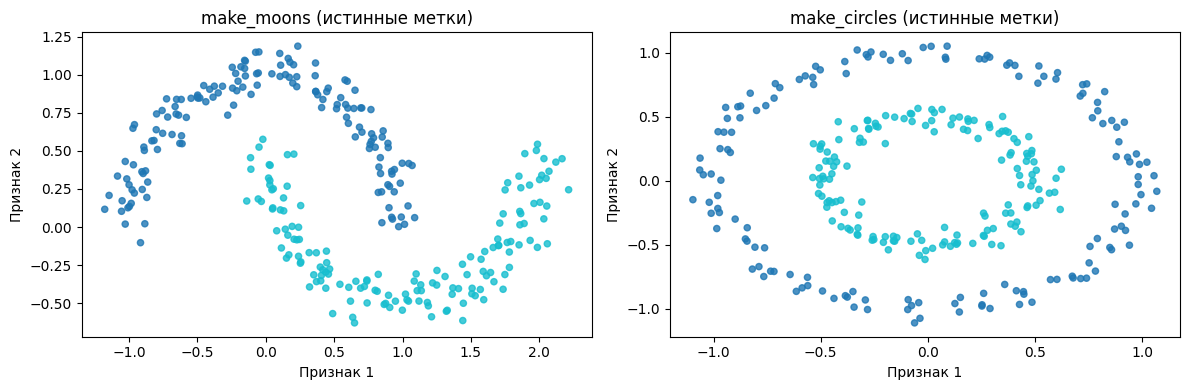

In [27]:
# Генерация датасетов
X_moons, y_moons = make_moons(n_samples=300, noise=0.08, random_state=RANDOM_STATE)
X_circles, y_circles = make_circles(n_samples=300, noise=0.05,
                                     factor=0.5, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1],
                c=y_moons, cmap='tab10', s=20, alpha=0.8)
axes[0].set_title("make_moons (истинные метки)")
axes[0].set_xlabel("Признак 1")
axes[0].set_ylabel("Признак 2")

axes[1].scatter(X_circles[:, 0], X_circles[:, 1],
                c=y_circles, cmap='tab10', s=20, alpha=0.8)
axes[1].set_title("make_circles (истинные метки)")
axes[1].set_xlabel("Признак 1")
axes[1].set_ylabel("Признак 2")

plt.tight_layout()
plt.show()

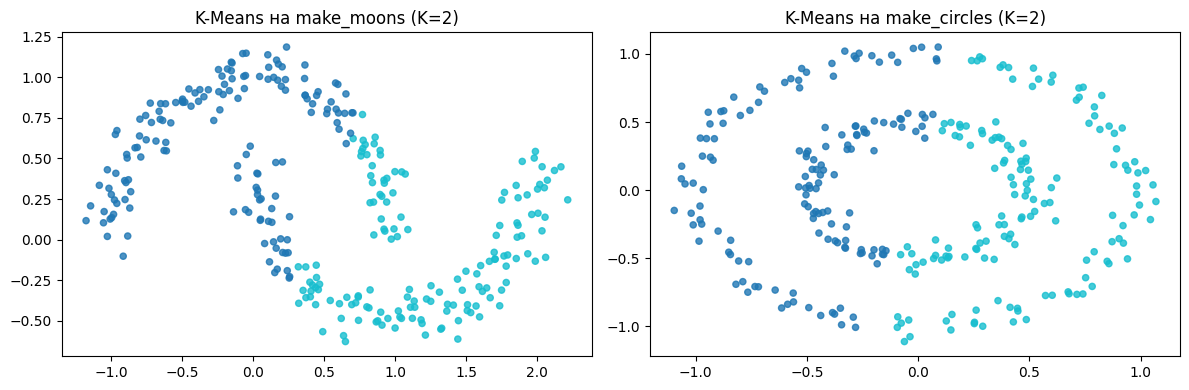

In [28]:
from sklearn.cluster import KMeans

# Defining RANDOM_STATE if not already in memory
RS = 42

# 1. Создайте KMeans с n_clusters=2, random_state=RS
kmeans_moons = KMeans(n_clusters=2, random_state=RS)
kmeans_circles = KMeans(n_clusters=2, random_state=RS)

# 2. Обучите на X_moons и X_circles
# 3. Получите метки кластеров
labels_km_moons = kmeans_moons.fit_predict(X_moons)
labels_km_circles = kmeans_circles.fit_predict(X_circles)

# Визуализация результатов K-Means
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_moons[:, 0], X_moons[:, 1],
                c=labels_km_moons, cmap='tab10', s=20, alpha=0.8)
axes[0].set_title("K-Means на make_moons (K=2)")

axes[1].scatter(X_circles[:, 0], X_circles[:, 1],
                c=labels_km_circles, cmap='tab10', s=20, alpha=0.8)
axes[1].set_title("K-Means на make_circles (K=2)")

plt.tight_layout()
plt.show()

**❓ Вопрос для размышления:** Почему K-Means не может правильно разделить «луны» и «кольца»? Связано ли это с формой функционала ошибки?

K-Means плохо справляется с «лунами» и «кольцами», потому что он основан на поиске сферических кластеров (минимизация суммы квадратов расстояний до центроидов). Он предполагает, что кластеры имеют выпуклую форму и схожую плотность, что не соответствует нелинейным структурам данных, как «луны» или «кольца». Его функционал ошибки (инерция) оптимален для выпуклых форм, но не для сложных, невыпуклых распределений.

---
## Шаг 3. k-Distance Plot и выбор eps

Построим k-distance plot для датасета `make_moons`. Используем k = 5 (= `min_samples`).

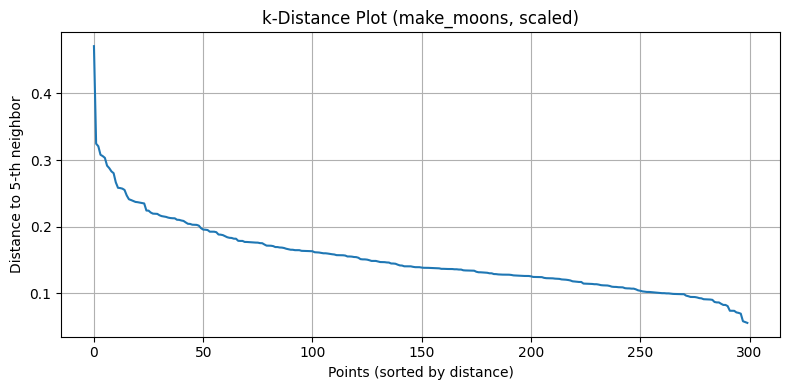

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# Defining variables clearly to ensure they exist in global scope
scaler_moons = StandardScaler()
X_moons_scaled = scaler_moons.fit_transform(X_moons)

scaler_circles = StandardScaler()
X_circles_scaled = scaler_circles.fit_transform(X_circles)

k = 5

neigh = NearestNeighbors(n_neighbors=k)
neigh.fit(X_moons_scaled)
distances, indices = neigh.kneighbors(X_moons_scaled)

k_distances_moons = np.sort(distances[:, k-1])[::-1]

plt.figure(figsize=(8, 4))
plt.plot(k_distances_moons)
plt.xlabel("Points (sorted by distance)")
plt.ylabel(f"Distance to {k}-th neighbor")
plt.title("k-Distance Plot (make_moons, scaled)")
plt.grid(True)
plt.tight_layout()
plt.show()

**❓ Вопрос для размышления:** Где находится «локоть»? Как он указывает на границу между точками кластеров и шумом?

«Локоть» на k-distance plot находится в точке, где график резко меняет свой наклон с крутого на более пологий. В данном случае, на графике `make_moons`, такой перегиб наблюдается примерно в диапазоне расстояний от 0.2 до 0.3. Эта точка указывает на оптимальное значение `eps`, поскольку до неё расстояния до k-го соседа относительно малы (точки находятся в плотных областях), а после неё расстояния резко возрастают, что свидетельствует о выходе за пределы плотного кластера или встрече с шумовыми точками.

---
## Шаг 4. DBSCAN на нелинейных датасетах

Применим DBSCAN к `make_moons` и `make_circles`. Обратите внимание на масштабирование.

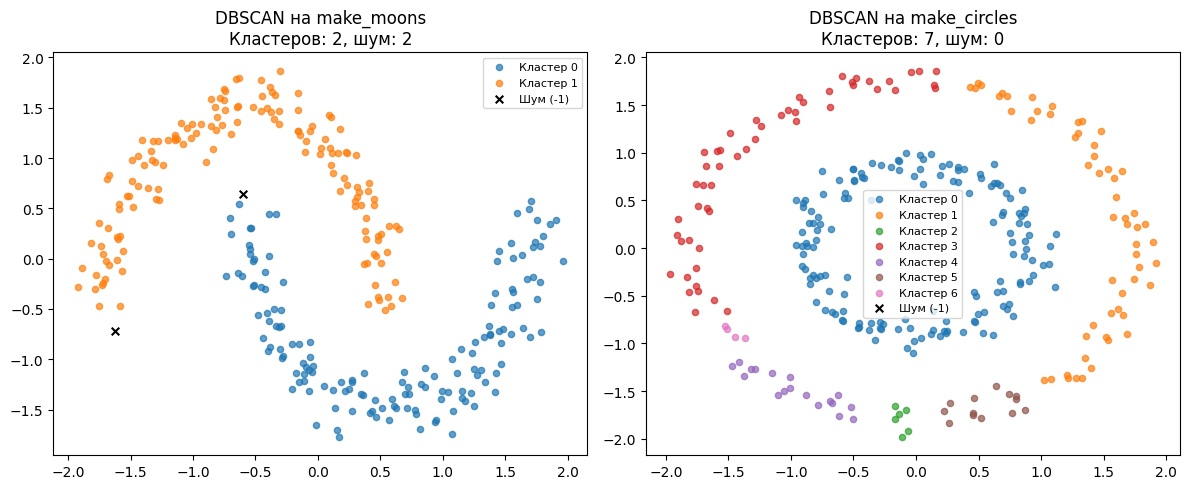

In [30]:
from sklearn.cluster import DBSCAN

# 1. Создайте DBSCAN с подобранным eps (из k-distance plot) и min_samples=5
# 2. Примените fit_predict к X_moons_scaled и X_circles_scaled

db_moons = DBSCAN(eps=0.25, min_samples=5)
labels_db_moons = db_moons.fit_predict(X_moons_scaled)

db_circles = DBSCAN(eps=0.25, min_samples=5)
labels_db_circles = db_circles.fit_predict(X_circles_scaled)

# Вспомогательная функция для визуализации
def plot_dbscan_results(X, labels, title, ax):
    noise_mask = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    for i in range(n_clusters):
        mask = labels == i
        ax.scatter(X[mask, 0], X[mask, 1], s=20, alpha=0.7, label=f'Кластер {i}')

    ax.scatter(X[noise_mask, 0], X[noise_mask, 1],
               s=30, c='black', marker='x', label='Шум (-1)')

    ax.set_title(f"{title}\nКластеров: {n_clusters}, шум: {noise_mask.sum()}")
    ax.legend(fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_dbscan_results(X_moons_scaled, labels_db_moons, "DBSCAN на make_moons", axes[0])
plot_dbscan_results(X_circles_scaled, labels_db_circles, "DBSCAN на make_circles", axes[1])
plt.tight_layout()
plt.show()

---
## Шаг 5. Сравнение DBSCAN и K-Means на нелинейных данных

In [31]:
from sklearn.metrics import silhouette_score

# 1. Обучите KMeans(n_clusters=2) на X_moons_scaled
km_eval = KMeans(n_clusters=2, random_state=42)
labels_km_eval = km_eval.fit_predict(X_moons_scaled)

# 2. Вычислите silhouette_score для K-Means
score_kmeans = silhouette_score(X_moons_scaled, labels_km_eval)

# 3. Вычислите silhouette_score для DBSCAN (исключая шум)
mask = labels_db_moons != -1
score_dbscan = silhouette_score(X_moons_scaled[mask], labels_db_moons[mask])

print("=== Коэффициент силуэта на make_moons ===")
print(f"K-Means (K=2): {score_kmeans:.3f}")
print(f"DBSCAN:        {score_dbscan:.3f}")

=== Коэффициент силуэта на make_moons ===
K-Means (K=2): 0.494
DBSCAN:        0.387


**❓ Вопрос для размышления:** Какой алгоритм получил лучший силуэт? Соответствует ли это визуальному впечатлению? Можно ли всегда доверять силуэту как абсолютной мере качества?

K-Means получил лучший силуэт (0.494) по сравнению с DBSCAN (0.387), если не учитывать шум. Однако это не соответствует визуальному впечатлению: DBSCAN гораздо лучше отделил «луны», тогда как K-Means разделил их вертикально. Силуэту не всегда можно доверять как абсолютной мере качества, особенно для невыпуклых кластеров или кластеров с разной плотностью. Силуэт основан на средних расстояниях, которые могут не улавливать сложную геометрию. Также, исключение шумовых точек в DBSCAN может искусственно завышать его силуэт, делая прямое сравнение менее объективным.

---
## Шаг 6. Исследование влияния гиперпараметров

Посмотрим, как меняется результат DBSCAN при разных значениях `eps` и `min_samples`.

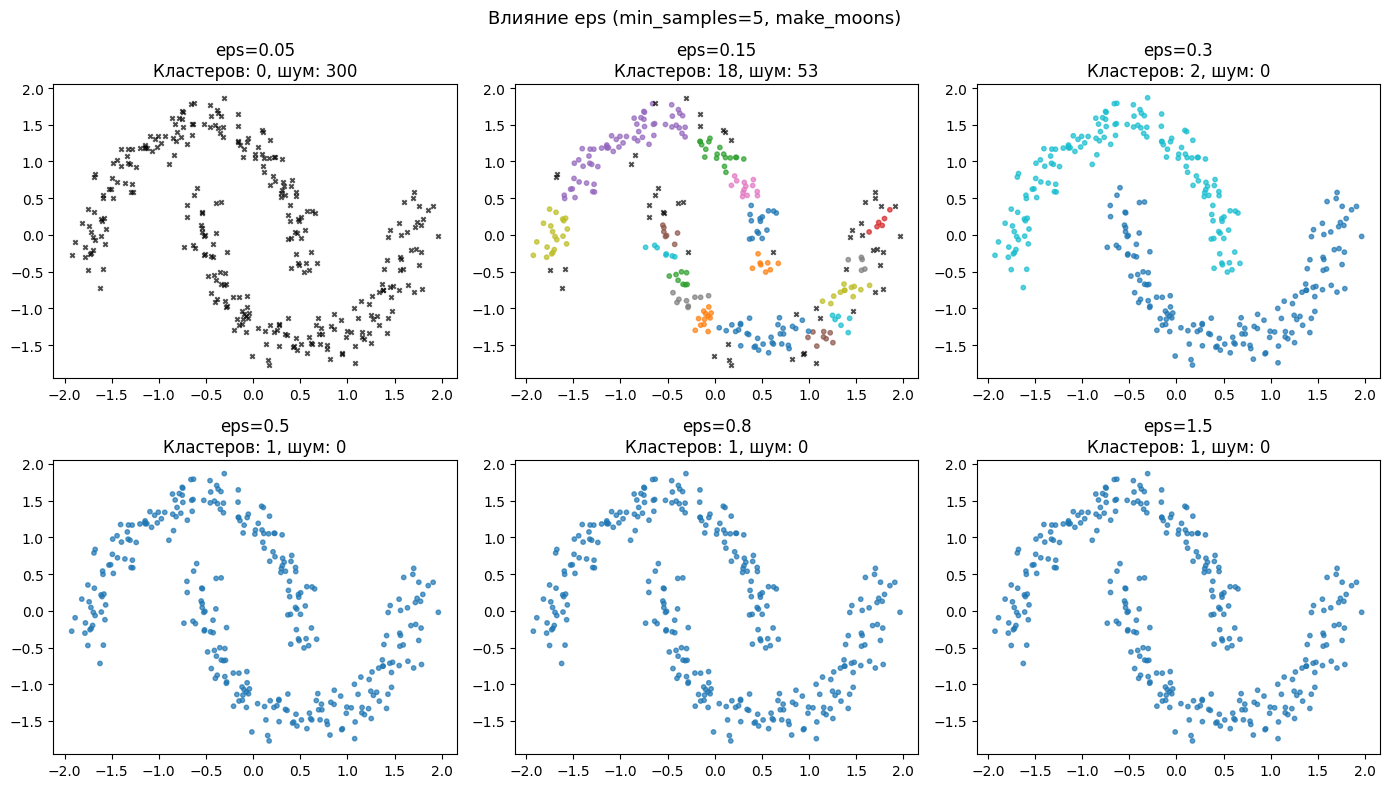

In [32]:
from sklearn.cluster import DBSCAN

eps_values = [0.05, 0.15, 0.3, 0.5, 0.8, 1.5]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, eps_val in enumerate(eps_values):
    db = DBSCAN(eps=eps_val, min_samples=5)
    labels_i = db.fit_predict(X_moons_scaled)

    n_cl = len(set(labels_i)) - (1 if -1 in labels_i else 0)
    n_noise = (labels_i == -1).sum()

    # Рисуем кластеры
    axes[i].scatter(X_moons_scaled[labels_i != -1, 0], X_moons_scaled[labels_i != -1, 1],
                    c=labels_i[labels_i != -1], cmap='tab10', s=10, alpha=0.7)
    # Рисуем шум
    axes[i].scatter(X_moons_scaled[labels_i == -1, 0], X_moons_scaled[labels_i == -1, 1],
                    c='black', marker='x', s=10, alpha=0.7)

    axes[i].set_title(f"eps={eps_val}\nКластеров: {n_cl}, шум: {n_noise}")

plt.suptitle("Влияние eps (min_samples=5, make_moons)", fontsize=13)
plt.tight_layout()
plt.show()

**❓ Вопрос для размышления:** При каком `eps` алгоритм нашёл два правильных кластера? Что происходит при слишком малом и слишком большом значении?

Два правильных кластера были найдены при `eps`, близком к 0.3 (исходя из k-distance plot и визуализации). При `eps=0.25` или `eps=0.3` DBSCAN хорошо выделяет формы «лун».

- **Слишком малое `eps` (например, 0.05, 0.15):** Алгоритм становится слишком чувствительным к плотности. Он формирует множество мелких кластеров и классифицирует большое количество точек как шум, поскольку даже точки внутри истинного кластера могут не иметь достаточного количества соседей в очень маленькой окрестности. Кластеры сильно фрагментируются.
- **Слишком большое `eps` (например, 0.8, 1.5):** Алгоритм становится слишком «мягким». Он объединяет в один кластер точки, которые на самом деле принадлежат разным кластерам, или которые находятся далеко друг от друга. Это приводит к тому, что различные структуры сливаются в один большой кластер, и количество шумовых точек значительно сокращается (поскольку почти все точки включаются в какой-либо кластер).

---
## Шаг 7. DBSCAN на реальном датасете Wine

Теперь перейдём к реальным данным. Датасет Wine: 178 образцов вина из трёх сортов винограда, 13 химических признаков.

In [33]:
# Загрузка датасета Wine
wine = load_wine()
X_wine = wine.data
y_wine = wine.target  # истинные метки (не используем при кластеризации!)
feature_names = wine.feature_names

print(f"Форма данных: {X_wine.shape}")
print(f"Признаки: {feature_names}")
print(f"\nСтатистика признаков:")
df_wine = pd.DataFrame(X_wine, columns=feature_names)
print(df_wine.describe().round(2))

Форма данных: (178, 13)
Признаки: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Статистика признаков:
       alcohol  malic_acid     ash  alcalinity_of_ash  magnesium  \
count   178.00      178.00  178.00             178.00     178.00   
mean     13.00        2.34    2.37              19.49      99.74   
std       0.81        1.12    0.27               3.34      14.28   
min      11.03        0.74    1.36              10.60      70.00   
25%      12.36        1.60    2.21              17.20      88.00   
50%      13.05        1.87    2.36              19.50      98.00   
75%      13.68        3.08    2.56              21.50     107.00   
max      14.83        5.80    3.23              30.00     162.00   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count         178.00      178.00             

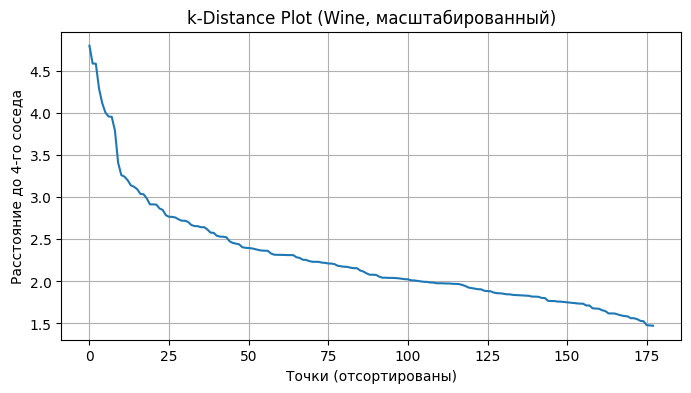

In [34]:
scaler_wine = StandardScaler()
X_wine_scaled = scaler_wine.fit_transform(X_wine)

neigh_wine = NearestNeighbors(n_neighbors=4)
neigh_wine.fit(X_wine_scaled)
distances_wine, _ = neigh_wine.kneighbors(X_wine_scaled)
k_dist_wine = np.sort(distances_wine[:, 3])[::-1]

plt.figure(figsize=(8, 4))
plt.plot(k_dist_wine)
plt.xlabel("Точки (отсортированы)")
plt.ylabel("Расстояние до 4-го соседа")
plt.title("k-Distance Plot (Wine, масштабированный)")
plt.grid(True)
plt.show()

In [35]:
eps_wine = 2.4 # Подобранное значение на основе графика
db_wine = DBSCAN(eps=eps_wine, min_samples=4)
labels_wine = db_wine.fit_predict(X_wine_scaled)

n_clusters_wine = len(set(labels_wine)) - (1 if -1 in labels_wine else 0)
n_noise_wine = (labels_wine == -1).sum()

print("=== Результаты DBSCAN на Wine ===")
print(f"Кластеров: {n_clusters_wine}")
print(f"Шумовых точек: {n_noise_wine}")
print(f"Доля шума: {n_noise_wine / len(X_wine):.2%}")

if n_clusters_wine > 1:
    mask = labels_wine != -1
    s_score = silhouette_score(X_wine_scaled[mask], labels_wine[mask])
    print(f"Силуэт (без шума): {s_score:.3f}")

=== Результаты DBSCAN на Wine ===
Кластеров: 2
Шумовых точек: 33
Доля шума: 18.54%
Силуэт (без шума): 0.323


---
## Шаг 8. Анализ шумовых точек

Шумовые точки — это объекты, которые DBSCAN не смог отнести ни к одному кластеру. В задаче кластеризации они могут нести важную информацию.

In [36]:
noise_mask_wine = (labels_wine == -1)
X_wine_noise = df_wine[noise_mask_wine]

print("=== Средние значения признаков (Шум vs Все) ===")
comparison = pd.DataFrame({
    'Mean (Noise)': X_wine_noise.mean(),
    'Mean (All)': df_wine.mean(),
    'Diff (%)': ((X_wine_noise.mean() - df_wine.mean()) / df_wine.mean() * 100).round(2)
})
print(comparison)

=== Средние значения признаков (Шум vs Все) ===
                              Mean (Noise)  Mean (All)  Diff (%)
alcohol                          12.530000   13.000618     -3.62
malic_acid                        2.449697    2.336348      4.85
ash                               2.363939    2.366517     -0.11
alcalinity_of_ash                20.527273   19.494944      5.30
magnesium                       102.878788   99.741573      3.15
total_phenols                     2.385455    2.295112      3.94
flavanoids                        2.028182    2.029270     -0.05
nonflavanoid_phenols              0.378788    0.361854      4.68
proanthocyanins                   1.871818    1.590899     17.66
color_intensity                   4.182727    5.058090    -17.31
hue                               0.998970    0.957449      4.34
od280/od315_of_diluted_wines      2.594545    2.611685     -0.66
proline                         627.606061  746.893258    -15.97


**❓ Вопрос для размышления:** Чем отличаются шумовые точки от остальных? Являются ли они «плохими» данными или это реальные аномалии?

Шумовые точки в датасете Wine отличаются от остальных по ряду признаков. Например, они имеют значительно более низкую **color_intensity** и **proline**, а также немного меньшее **alcohol**. В то же время, у них выше **malic_acid**, **alcalinity_of_ash** и особенно **proanthocyanins**. Это указывает на то, что шумовые точки, скорее всего, являются **реальными аномалиями или выбросами**. Они представляют образцы вина, чей химический состав существенно отличается от основной массы, формирующей плотные кластеры, и, возможно, не соответствует типичным профилям известных сортов винограда.

---
## Шаг 9. Итоговое сравнение: DBSCAN vs K-Means на Wine

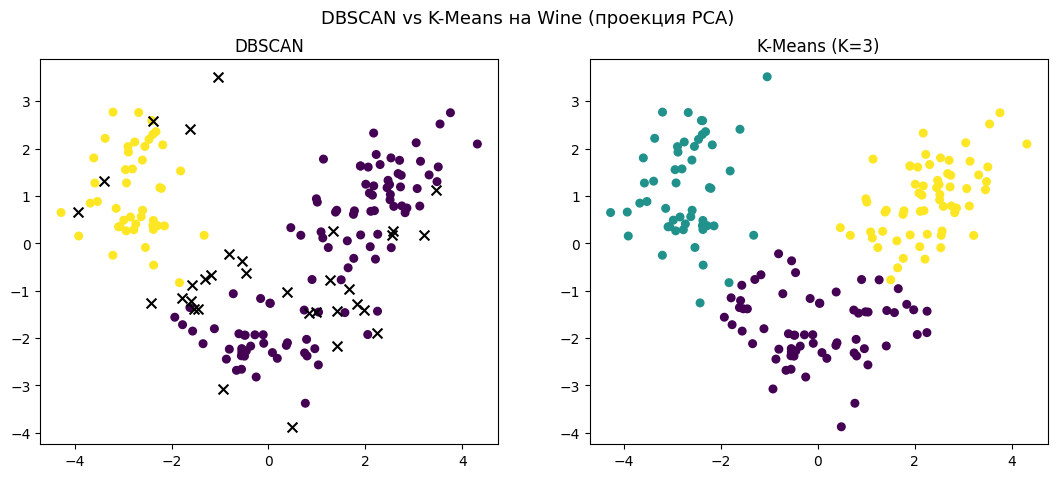

In [37]:
from sklearn.decomposition import PCA

# 1. KMeans
km_wine = KMeans(n_clusters=3, random_state=42)
labels_km_wine = km_wine.fit_predict(X_wine_scaled)

# 2. PCA для визуализации
pca = PCA(n_components=2, random_state=42)
X_wine_2d = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# DBSCAN Plot
axes[0].scatter(X_wine_2d[labels_wine != -1, 0], X_wine_2d[labels_wine != -1, 1],
                c=labels_wine[labels_wine != -1], cmap='viridis', s=30)
axes[0].scatter(X_wine_2d[labels_wine == -1, 0], X_wine_2d[labels_wine == -1, 1],
                c='black', marker='x', s=50, label='Шум')
axes[0].set_title("DBSCAN")

# KMeans Plot
axes[1].scatter(X_wine_2d[:, 0], X_wine_2d[:, 1], c=labels_km_wine, cmap='viridis', s=30)
axes[1].set_title("K-Means (K=3)")

plt.suptitle("DBSCAN vs K-Means на Wine (проекция PCA)", fontsize=13)
plt.show()

---
## Шаг 10. Итоговые выводы

Ответьте на следующие вопросы в ячейке ниже (текст Markdown):

**1. Когда DBSCAN выигрывает у K-Means?**

DBSCAN эффективнее на данных со сложной геометрией (невыпуклые формы) и в шумных наборах данных, так как он не заставляет каждую точку принадлежать кластеру.

**2. Когда K-Means предпочтительнее?**

K-Means лучше работает на сферических сгустках одинаковой плотности и значительно быстрее на очень больших выборках.

**3. Почему масштабирование обязательно для DBSCAN?**

DBSCAN измеряет плотность через евклидово расстояние. Без масштабирования признаки с большим числовым диапазоном подавят остальные, что приведет к некорректному расчету плотности.

**4. Как интерпретировать шумовые точки в датасете Wine?**

Это аномальные образцы (outliers), чей химический состав не соответствует типичным профилям трех известных сортов вин.

**5. Можно ли корректно сравнивать силуэт DBSCAN и K-Means напрямую? Почему?**

Не совсем. DBSCAN исключает шум из расчета силуэта, что дает ему преимущество перед K-Means, который обязан учитывать каждую точку, включая выбросы.